# Decision Tree for classification

Credit: [Jun He](https://www.ntu.ac.uk/staff-profiles/science-technology/jun-he) 

### Learning objectives
* Learn Sklean implementation of decision tree for classification
* Learn parameter tuning in decision tree

In [1]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import matplotlib.pyplot as plt 
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation

## Activity 1: Predict credit risk by decision tree
In this lab, you will build a decision tree model to predict customers' `credit risk` based on the same data as previous exercise

### Load Data and Understand Data  
The data `ClassifyRisk.csv` is the in the provided Jupyter notebook.  
* Print the accuracy of these models respectively 

*Question: which features are ordinal? which are nominal? Which are numerical?*


In [2]:
df = pd.read_csv("/kaggle/input/ml-datasets/ClassifyRisk.csv")
df.head(10)

,mortgage,loans,age,marital_status,income,risk
0,y,3,34,other,28060.70,bad loss
1,n,2,37,other,28009.34,bad loss
2,n,2,29,other,27614.60,bad loss
3,y,2,33,other,27287.18,bad loss
4,y,2,39,other,26954.06,bad loss
5,n,2,28,other,26271.86,bad loss
6,n,3,28,other,40445.00,bad loss
7,n,2,25,other,23888.30,bad loss
8,n,2,41,other,35249.25,bad loss
9,n,2,26,other,23518.88,bad loss


### Prepare Data 
A requirement by Sklearn classifiers is to convert categorical features into numerical ones.  

*Questions: which feature is OrdinalEncoder() applied to? which feature is OneHotEncoder (pandas.get_dummies) applied to?* 

Encode all categorical features. Refer to lecture notes.   

In [3]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder() # create an encoder with order
df[['mortgage','risk']] = encoder.fit_transform(df[['mortgage','risk']]) # fit encoder with data and transfer data 
df.head(5)

,mortgage,loans,age,marital_status,income,risk
0,1.0,3,34,other,28060.70,0.0
1,0.0,2,37,other,28009.34,0.0
2,0.0,2,29,other,27614.60,0.0
3,1.0,2,33,other,27287.18,0.0
4,1.0,2,39,other,26954.06,0.0


In [4]:
df = pd.get_dummies(df,prefix=['marital_status'], columns = ['marital_status'])
df.head(5)

,mortgage,loans,age,income,risk,marital_status_married,marital_status_other,marital_status_single
0,1.0,3,34,28060.70,0.0,False,True,False
1,0.0,2,37,28009.34,0.0,False,True,False
2,0.0,2,29,27614.60,0.0,False,True,False
3,1.0,2,33,27287.18,0.0,False,True,False
4,1.0,2,39,26954.06,0.0,False,True,False


In [5]:
column_name = 'risk'
column_0 = df.pop(column_name)
df.insert(7, column_name, column_0)
df.head(5)

,mortgage,loans,age,income,marital_status_married,marital_status_other,marital_status_single,risk
0,1.0,3,34,28060.70,False,True,False,0.0
1,0.0,2,37,28009.34,False,True,False,0.0
2,0.0,2,29,27614.60,False,True,False,0.0
3,1.0,2,33,27287.18,False,True,False,0.0
4,1.0,2,39,26954.06,False,True,False,0.0


* We sepearare features and target variable into `X` and `y` respectively

*Question:  which columns are predictors (features)? which column is class label (target)?*  

In [6]:
X = df.iloc[:,0:7]
y = df.iloc[:,7] 
print("Features X\n",X[0:5])
print("Target y\n", y[0:5])

Features X
    mortgage  loans  age    income  marital_status_married  \
0       1.0      3   34  28060.70                   False   
1       0.0      2   37  28009.34                   False   
2       0.0      2   29  27614.60                   False   
3       1.0      2   33  27287.18                   False   
4       1.0      2   39  26954.06                   False   

   marital_status_other  marital_status_single  
0                  True                  False  
1                  True                  False  
2                  True                  False  
3                  True                  False  
4                  True                  False  
Target y
 0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: risk, dtype: float64


### Build and train a model 
* Split features and target data `X, y` into traning data (70%) and test data (30%) as `X_train, X_test, y_train, y_test`.

*Question:  why data is split into training and test data sets*

In [7]:
import sklearn.model_selection as model_selection
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3, random_state =  1)

* build a decision tree model and train it on training data using  `DecisionTreeClassifier(criterion='gini')`  

In [8]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion='gini')
clf = clf.fit(X_train,y_train)
clf.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'random_state': None,
 'splitter': 'best'}

* Plot the decision tree using `tree.plot_tree`

Index(['mortgage', 'loans', 'age', 'income', 'marital_status_married',
       'marital_status_other', 'marital_status_single', 'risk'],
      dtype='object')


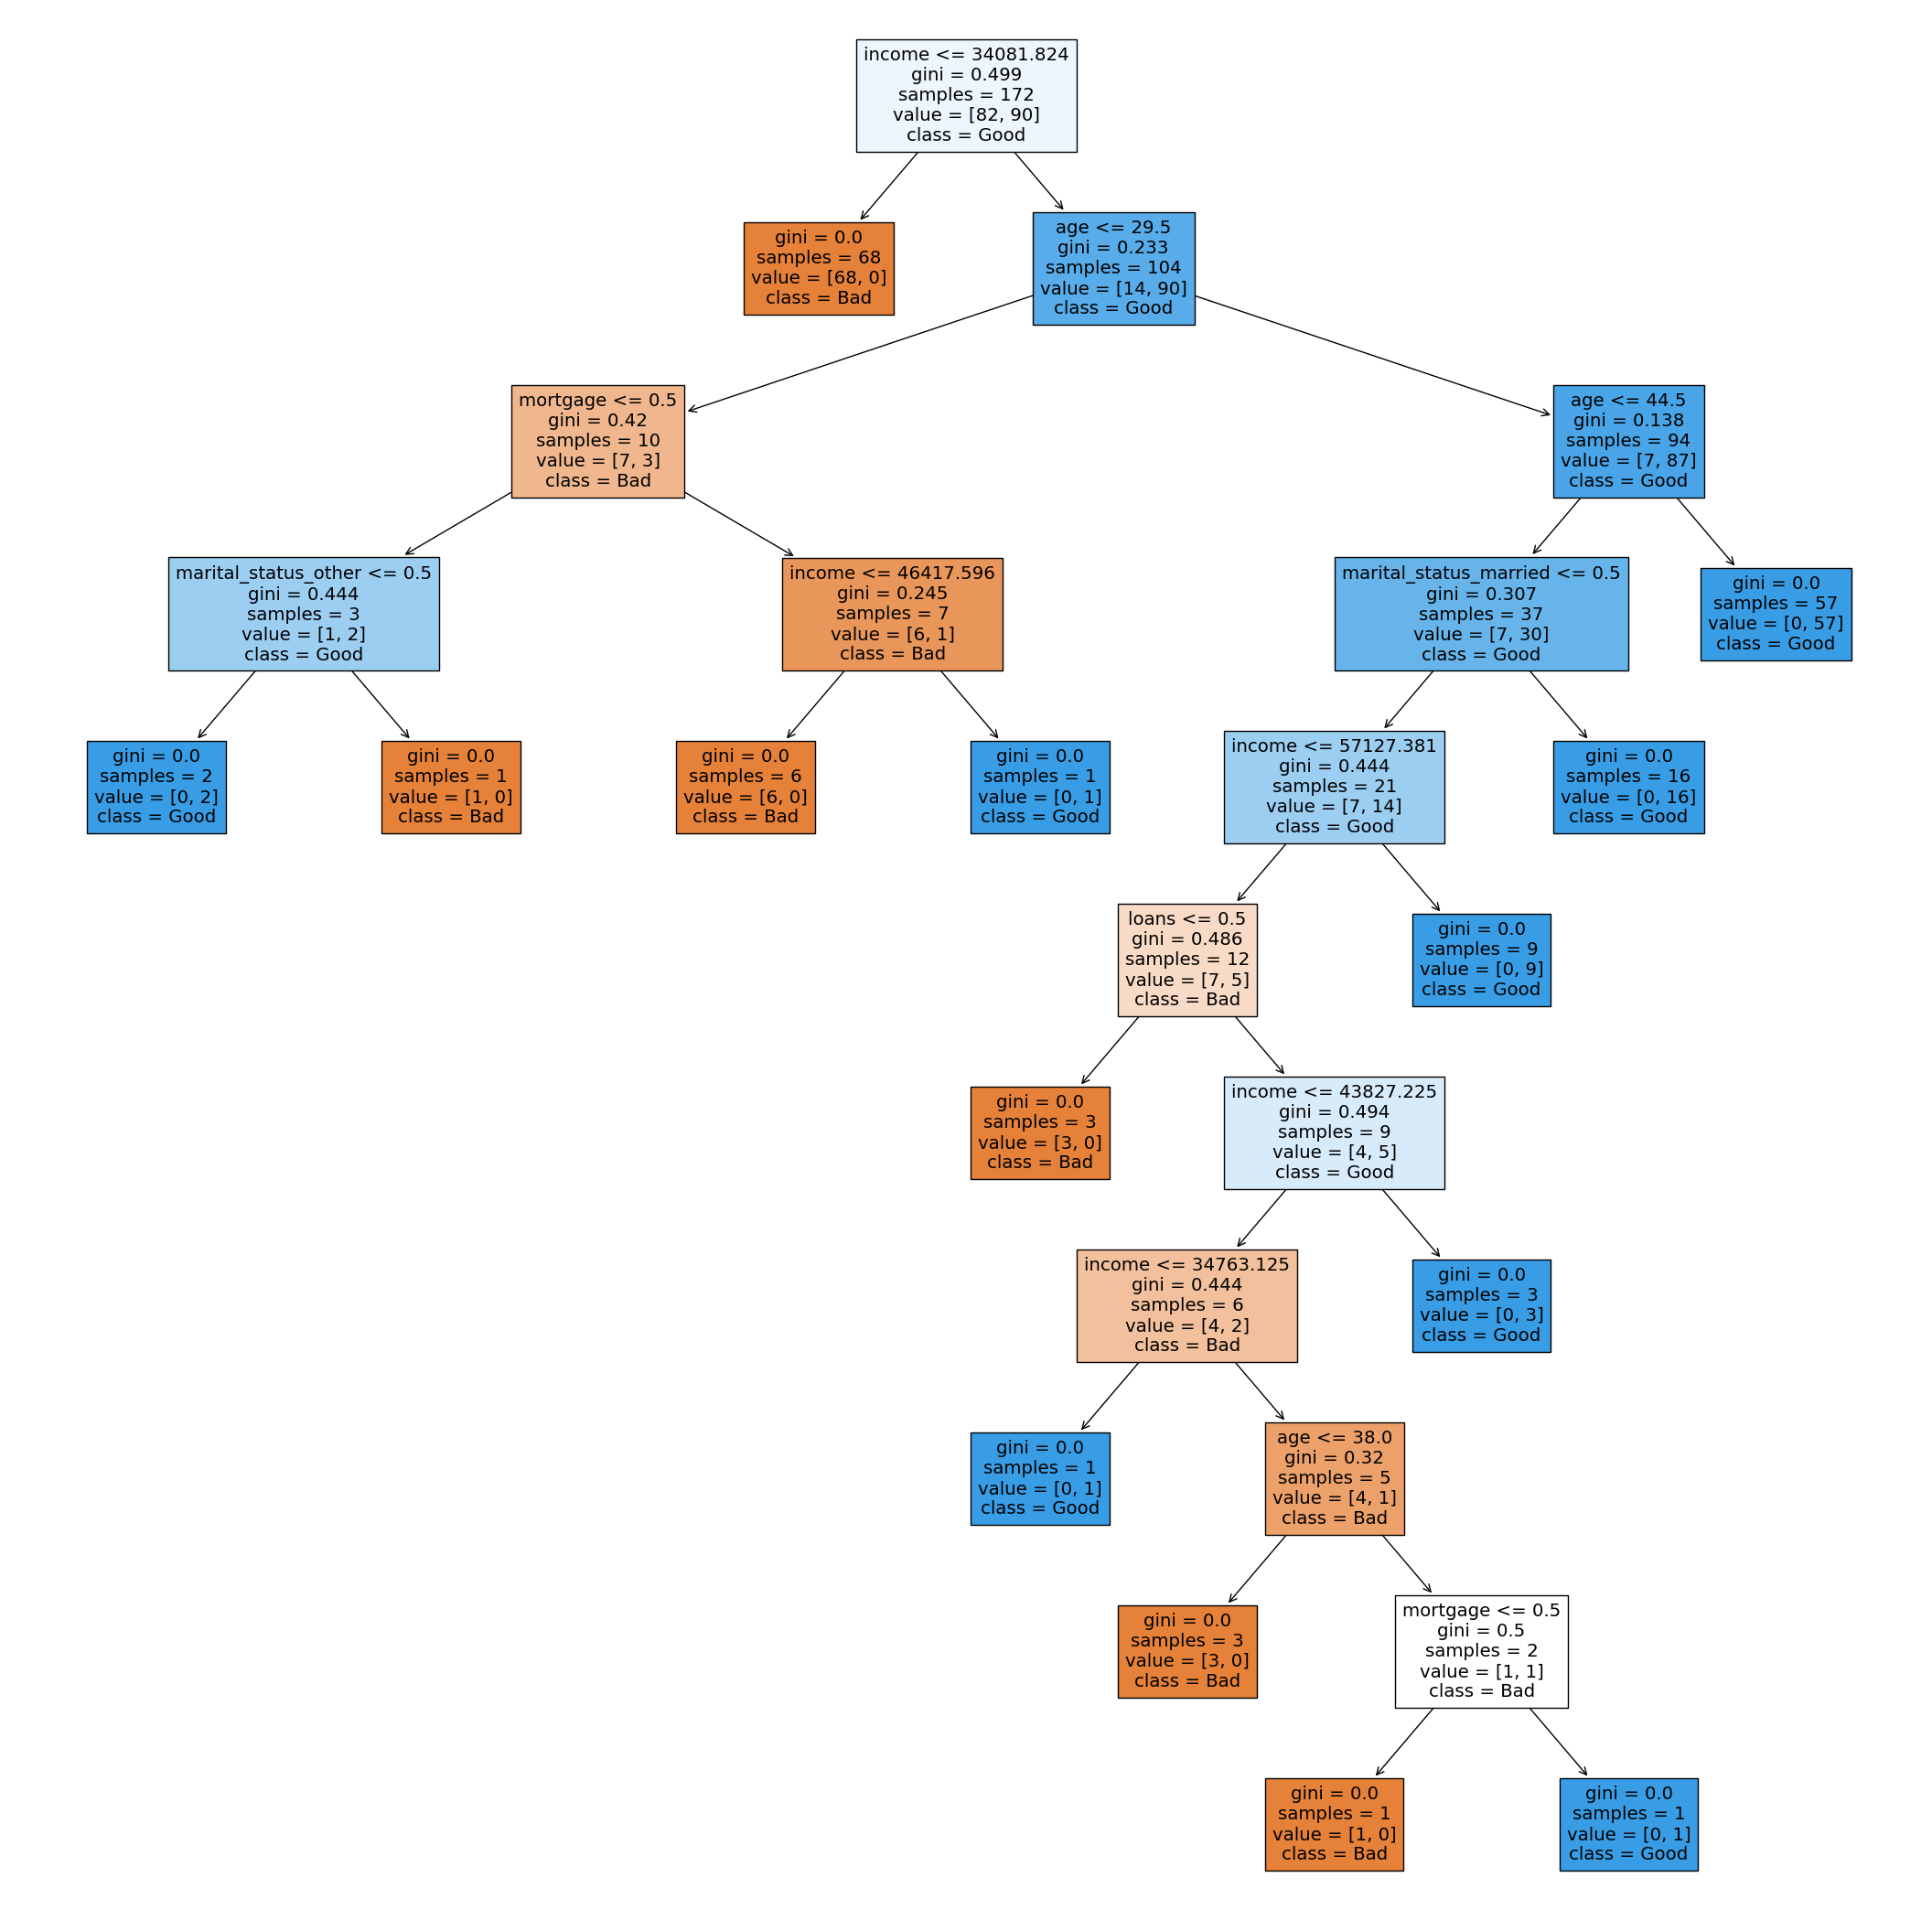

In [9]:
print(df.columns)
fig = plt.figure(figsize=(27,27)) 
_ = tree.plot_tree(clf, feature_names=df.columns, class_names=['Bad','Good'],filled=True)
 

### Evalaute the mode

*  Predict the accuracy using `metrics.accuracy_score()`

*Question: what is your accuracy result?*

In [10]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.972972972972973


## Activity 2 Tune Parameters
### Which Encoder: OneHot Encode or Ordinal Encoder?
You compare the performance of the decision tree between `OneHot Encode` and `Ordinal Encoder` 


* Read data into a data frame again.

Accuracy: 0.9324324324324325


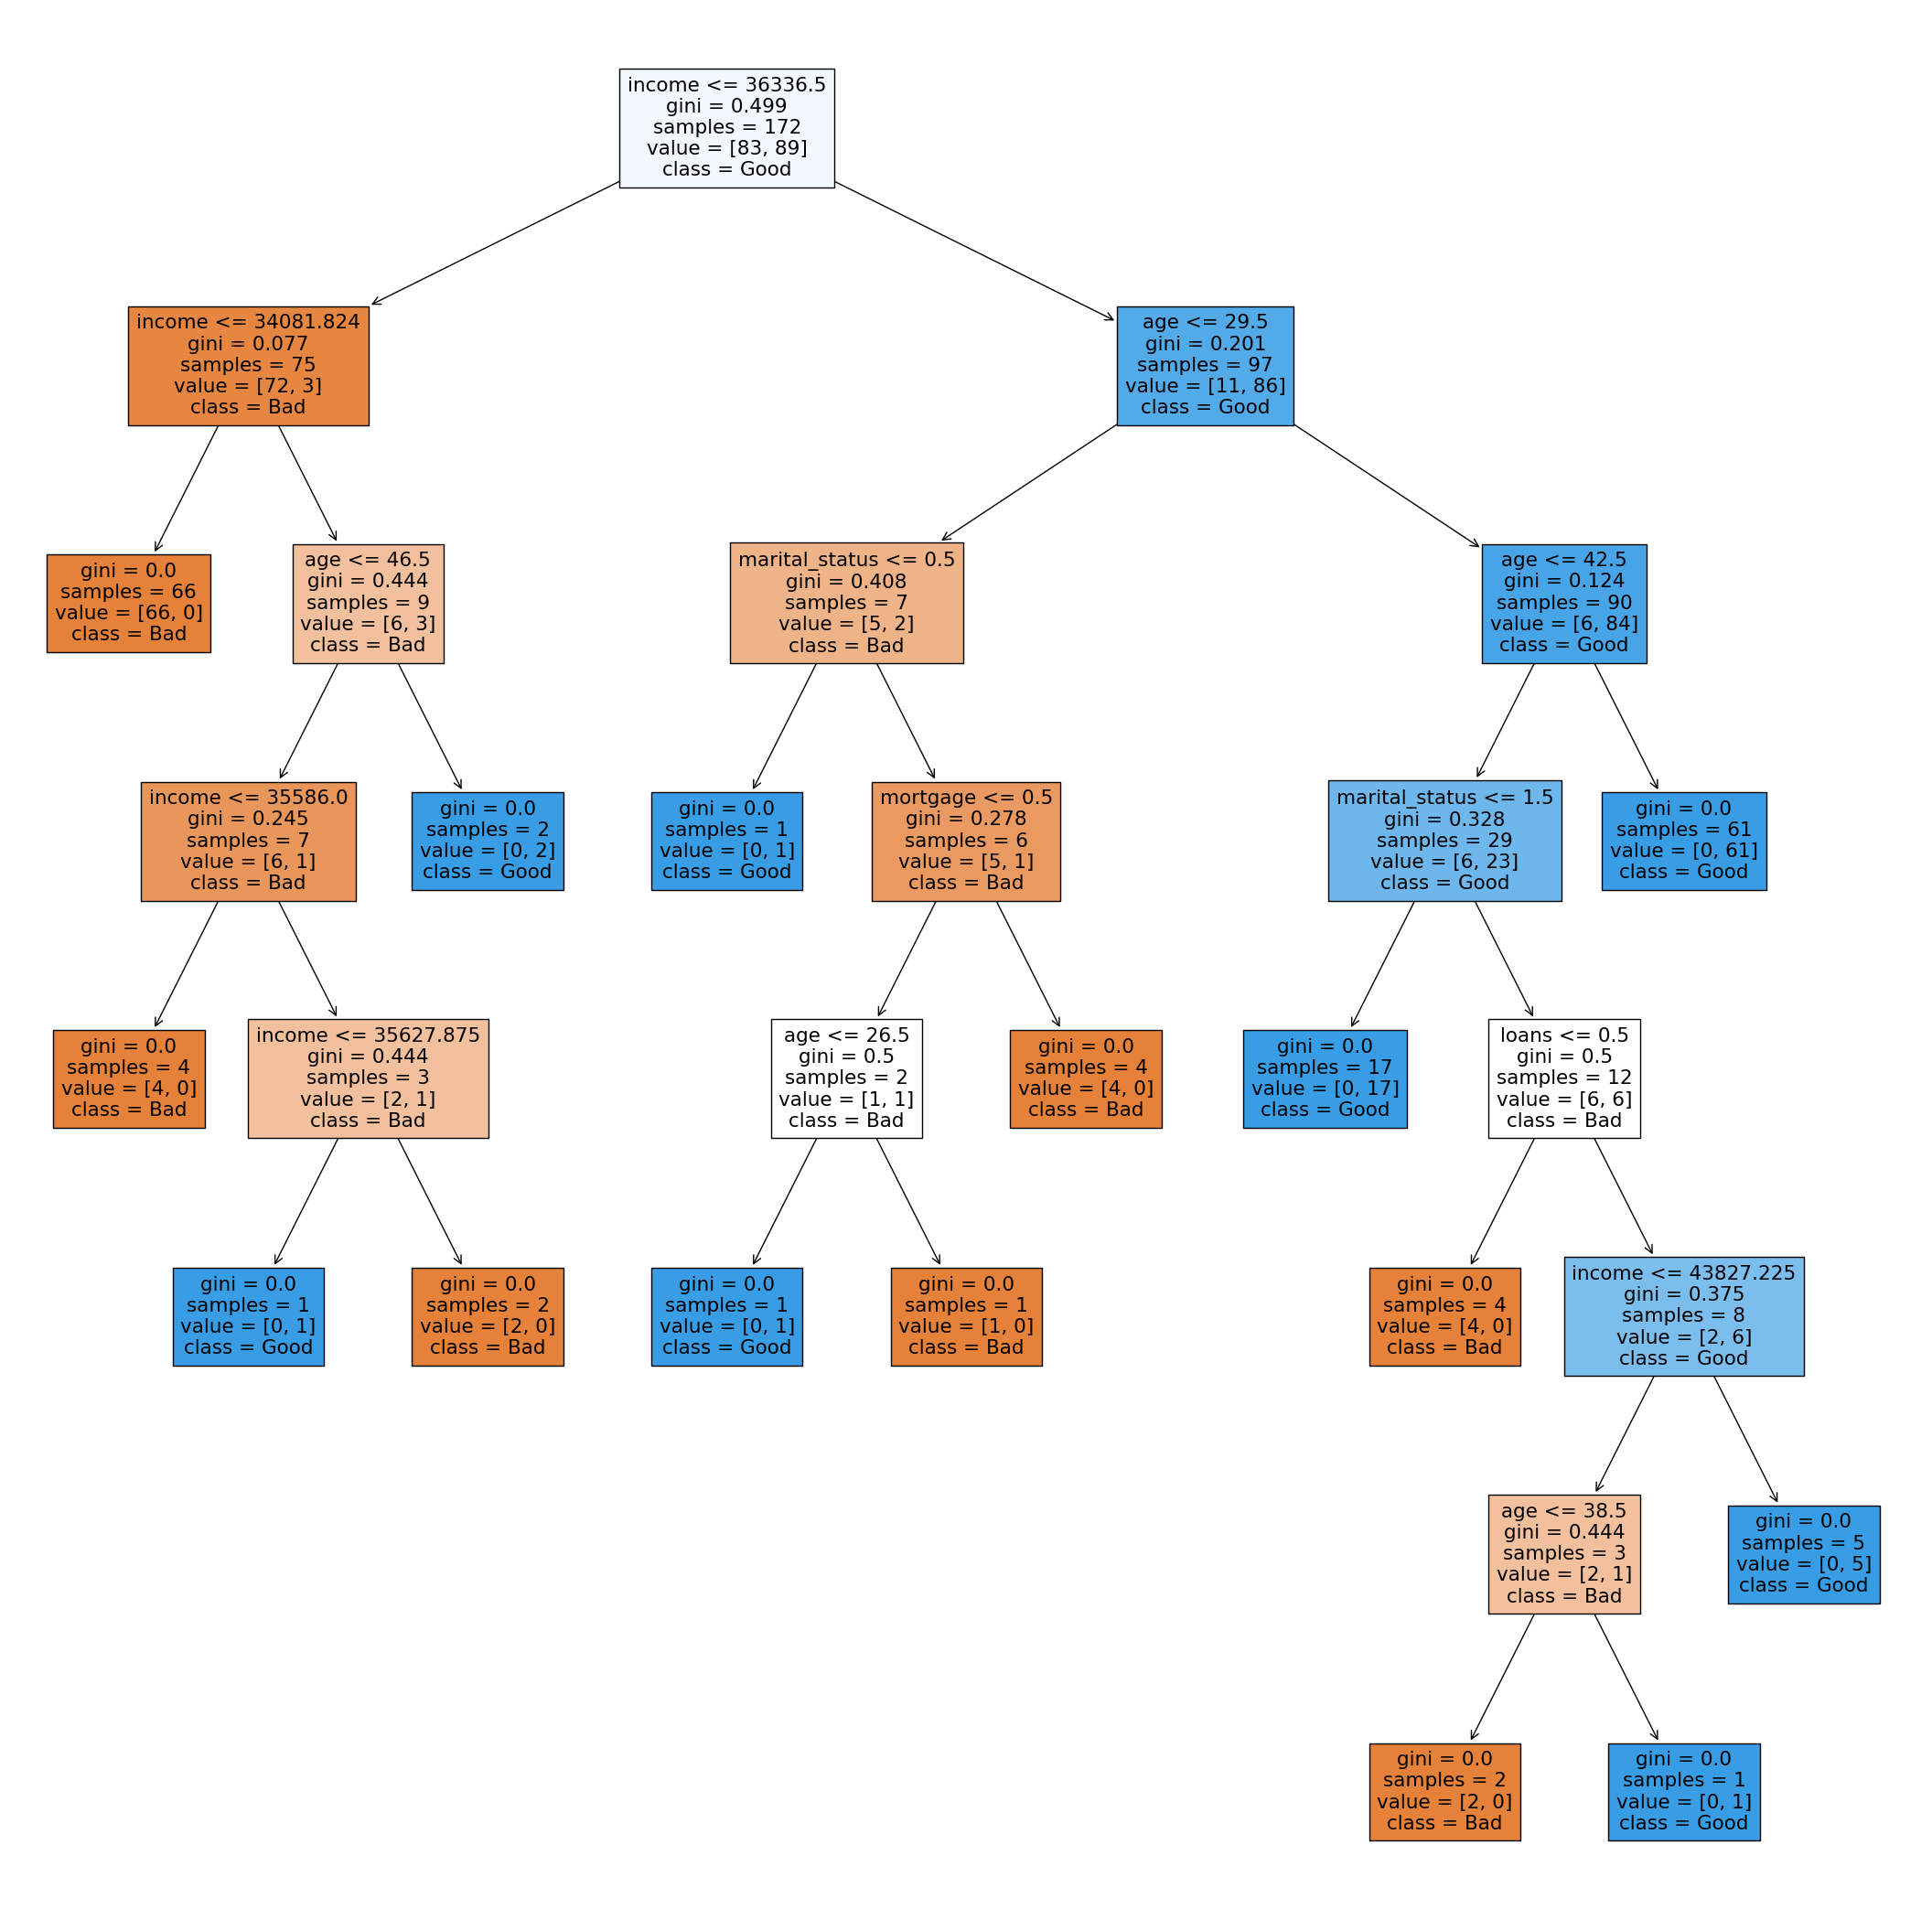

In [11]:
#read data
df = pd.read_csv("/kaggle/input/ml-datasets/ClassifyRisk.csv")

from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder() # create an encoder with order
df[['mortgage','marital_status','risk']] = encoder.fit_transform(df[['mortgage','marital_status','risk']]) # fit encoder with data and transfer data 

X = df.iloc[:,0:5] #predictors
y = df.iloc[:,5]  #target

#Split dataset into training set and test set
import sklearn.model_selection as model_selection
#split into training and test data
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3) 

# Create Decision Tree classifer object and train it on training data
clf = DecisionTreeClassifier(criterion='gini')
clf = clf.fit(X_train,y_train)

#plot tree
fig = plt.figure(figsize=(27,27)) 
_ = tree.plot_tree(clf, feature_names=df.columns, class_names=['Bad','Good'],filled=True)

#evaluate model on test data
y_pred = clf.predict(X_test)
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

### Tune criterion: “gini” or “entropy”
Criterion is used to measure the quality of a split. There are two supported criteria: `gini` for the Gini impurity and `entropy` for the information gain. Build a decision tree with `DecisionTreeClassifier(criterion='entropy')` and plot the tree. Compare the accuracy of the decision model with the two criteria.

*Question: which criterion leads to a better accuracy?*

Accuracy: 0.9459459459459459


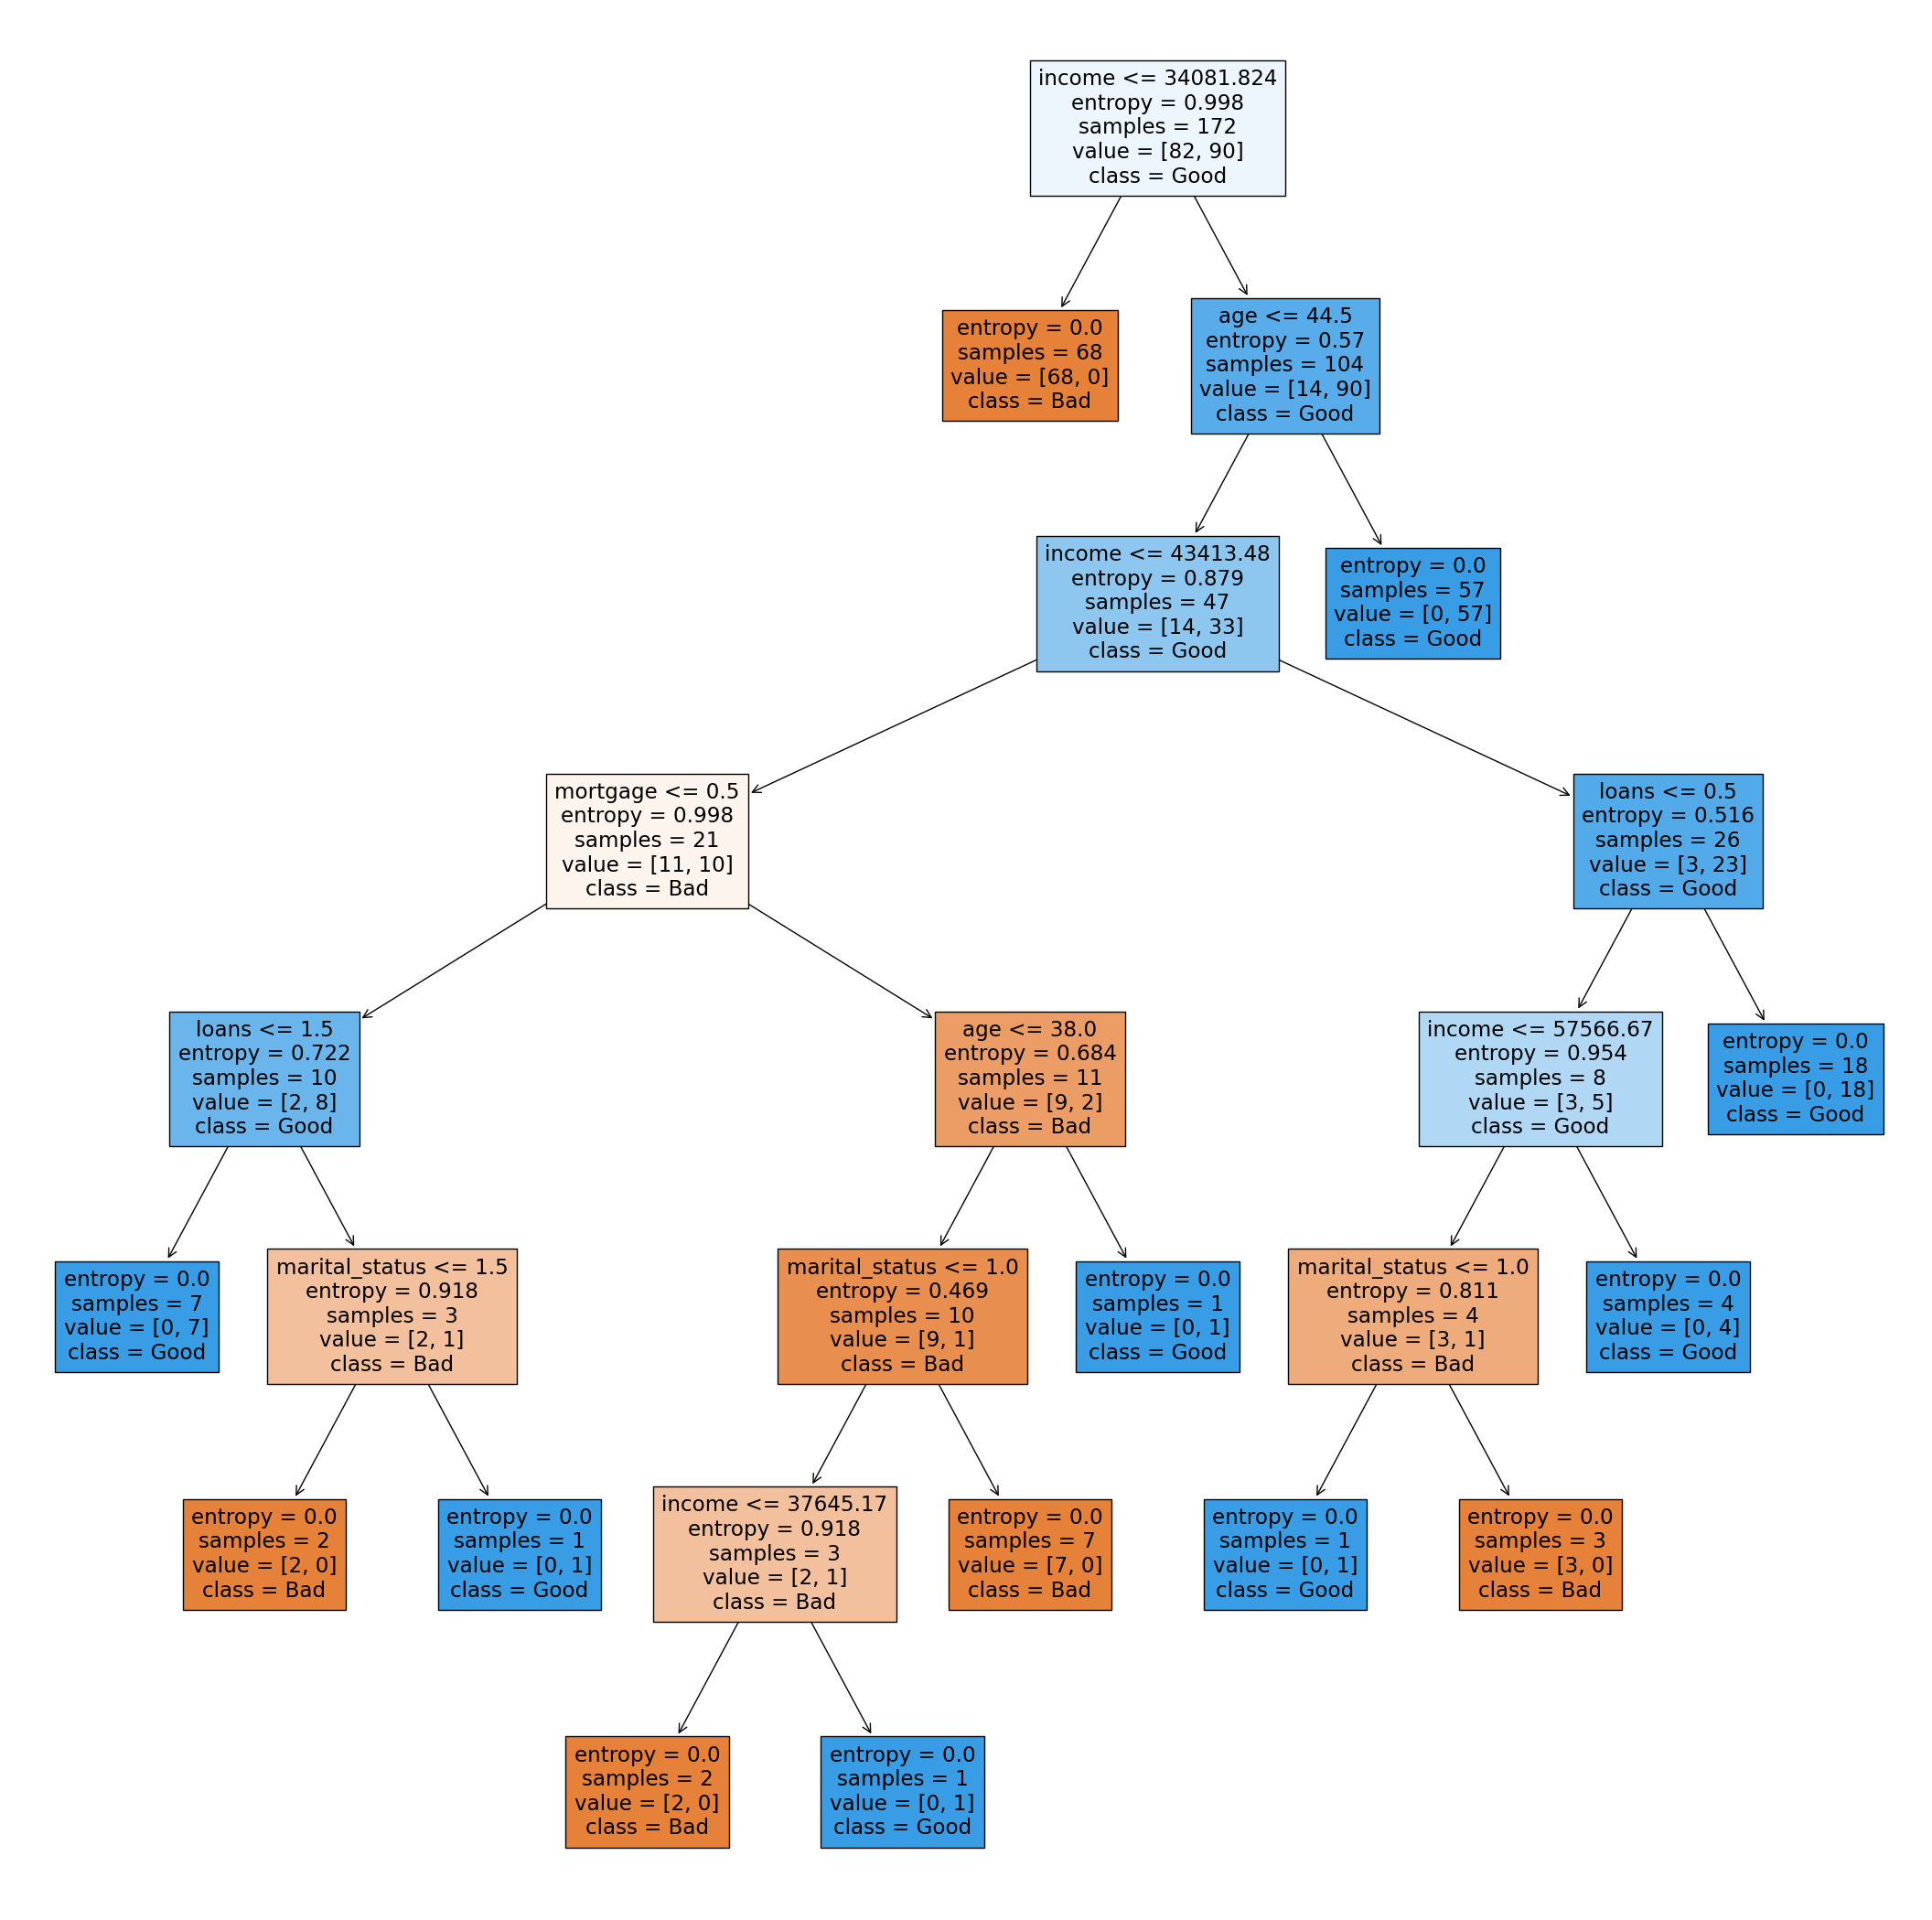

In [12]:
df = pd.read_csv("/kaggle/input/ml-datasets/ClassifyRisk.csv")
df.head(10)
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder() # create an encoder with order
df[['mortgage','marital_status']] = encoder.fit_transform(df[['mortgage','marital_status']]) # fit encoder with data and transfer data 
X = df.iloc[:,0:5]
y = df.iloc[:,5] 
#Split dataset into training set and test set
import sklearn.model_selection as model_selection
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3, random_state =  1)
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion='entropy')
clf = clf.fit(X_train,y_train)

fig = plt.figure(figsize=(27,27)) 
_ = tree.plot_tree(clf, feature_names=df.columns, class_names=['Bad','Good'],filled=True)
#Predict the response for test dataset
y_pred = clf.predict(X_test)
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

### Tune splitter: “best” or “random”
The splitter strategy is used to choose the split at each node. There are two supported strategies: “best” to choose the best split and “random” to choose the best random split.

Compare the accuracy of the model with the two strategies.


Accuracy: 0.9324324324324325


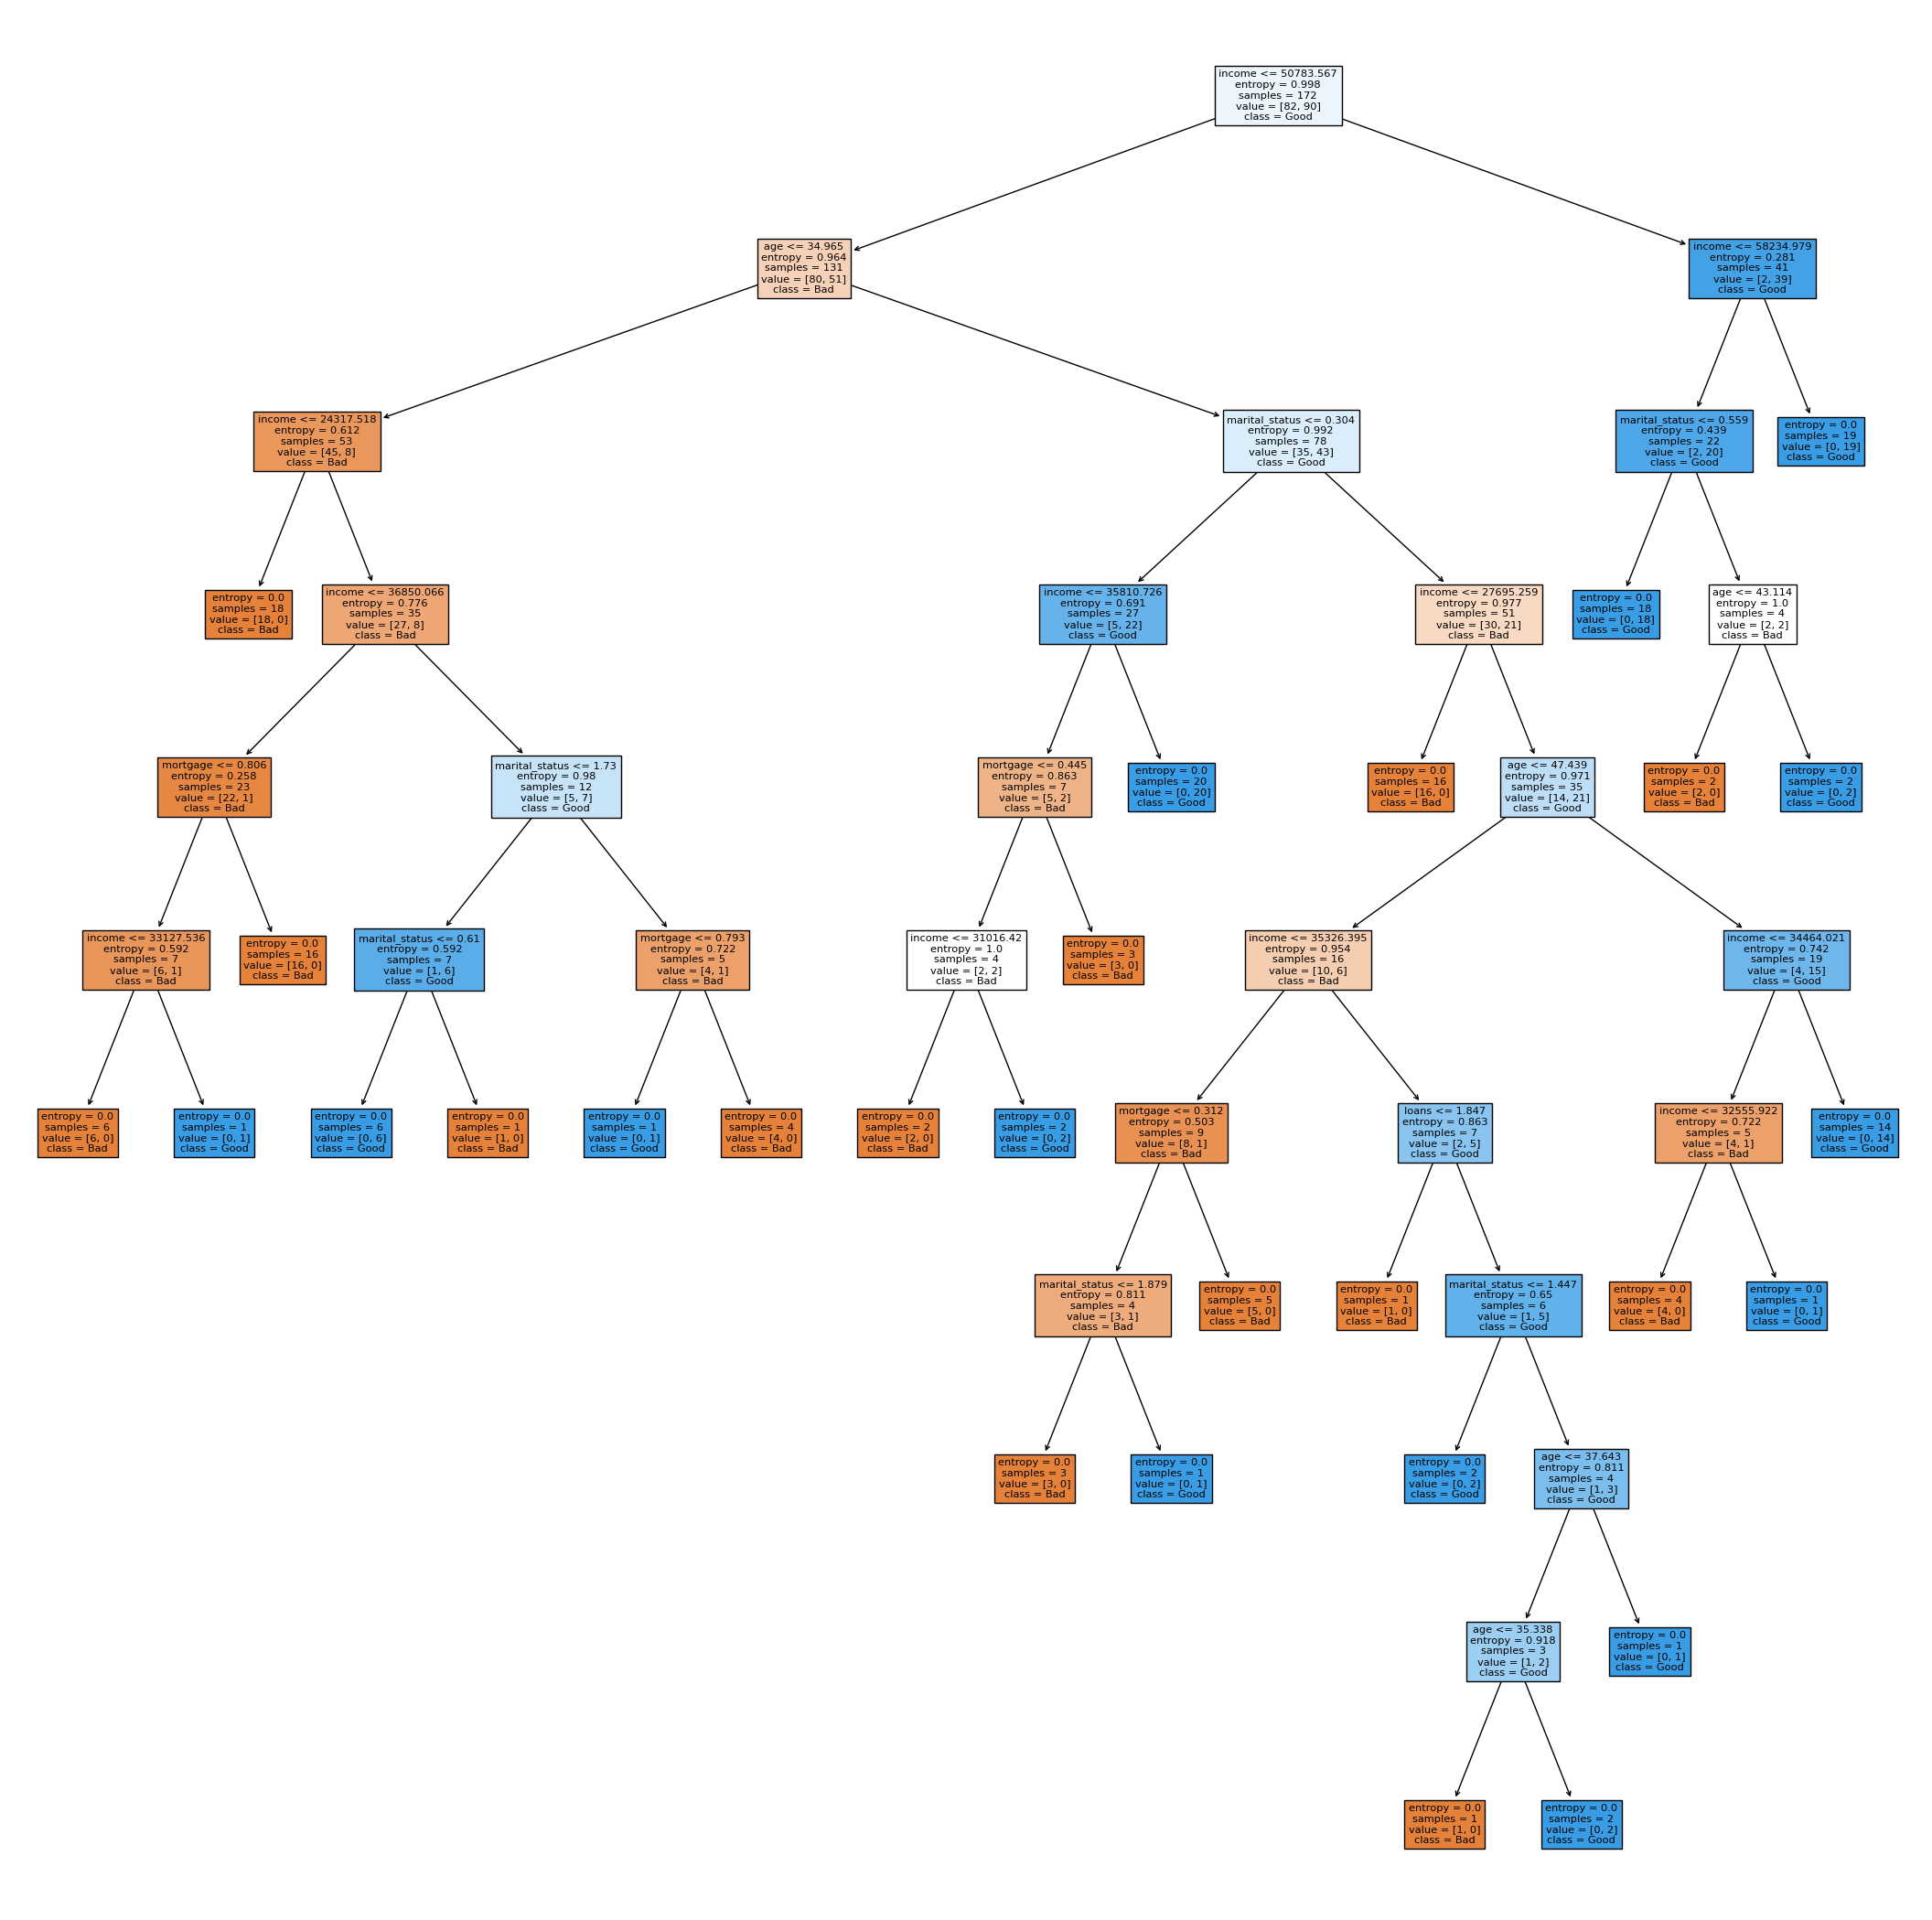

In [13]:
df = pd.read_csv("/kaggle/input/ml-datasets/ClassifyRisk.csv")
df.head(10)
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder() # create an encoder with order
df[['mortgage','marital_status']] = encoder.fit_transform(df[['mortgage','marital_status']]) # fit encoder with data and transfer data 

X = df.iloc[:,0:5]
y = df.iloc[:,5] 
#Split dataset into training set and test set
import sklearn.model_selection as model_selection
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.3, random_state =  1)
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion='entropy',splitter='random')
clf = clf.fit(X_train,y_train)
fig = plt.figure(figsize=(27,27)) 
_ = tree.plot_tree(clf, feature_names=df.columns, class_names=['Bad','Good'],filled=True)
#Predict labels of test data
y_pred = clf.predict(X_test)
# Print model Accuracy
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

## Reflect
Briefly note what you’ve learnt, found easy and found challenging in your Jupyter notebook. Keep these notes safe and maintain a reflective log for each lab session.

## Resources/references
1. Decision Trees: https://scikit-learn.org/stable/modules/tree.html